# 05 — Entanglement

Two-mode squeezed vacuum, logarithmic negativity, PPT/Simon separability,
the Duan et al. criterion, EPR joint correlations, and Gaussian steering.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvcircuit as cv

np.set_printoptions(precision=4, suppress=True)

## Two-mode squeezed vacuum (TMSV)

The workhorse entangled Gaussian state: `epr(r)` (or `two_mode_squeezed(r)`)
approaches a perfect EPR pair as `r -> infinity`. It's always pure, and its
reduced single-mode states are thermal, with entanglement entropy growing
with `r`.

In [2]:
for r in [0.2, 0.8, 1.5]:
    tmsv = cv.two_mode_squeezed(r)
    print(f"r={r}: is_pure={tmsv.is_pure()}  reduced mode is thermal with "
          f"nbar={tmsv.reduced([0]).mean_photon_number():.3f}  "
          f"entanglement entropy={tmsv.reduced([0]).von_neumann_entropy():.3f} bits")

r=0.2: is_pure=True  reduced mode is thermal with nbar=0.041  entanglement entropy=0.247 bits
r=0.8: is_pure=True  reduced mode is thermal with nbar=0.789  entanglement entropy=1.771 bits
r=1.5: is_pure=True  reduced mode is thermal with nbar=4.534  entanglement entropy=3.772 bits


## Logarithmic negativity and separability

`logarithmic_negativity` is an entanglement *monotone* (quantifies "how
entangled"); `is_separable` (the PPT/Simon test) is a yes/no check, exact
for a 1-vs-N-mode bipartition.

product state separable: True
TMSV(r=1) separable: False


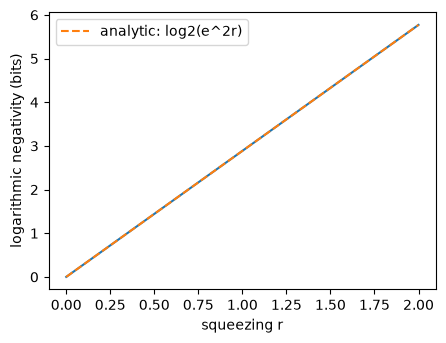

In [3]:
rs = np.linspace(0, 2.0, 40)
log_negs = [cv.logarithmic_negativity(cv.two_mode_squeezed(r), [0]) for r in rs]

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.plot(rs, log_negs)
ax.plot(rs, np.log2(np.exp(2 * rs)), "--", label="analytic: log2(e^2r)")
ax.set_xlabel("squeezing r")
ax.set_ylabel("logarithmic negativity (bits)")
ax.legend()

product_state = cv.squeezed(0.7) & cv.thermal(0.5)
print("product state separable:", cv.is_separable(product_state, [0]))
print("TMSV(r=1) separable:", cv.is_separable(cv.two_mode_squeezed(1.0), [0]))

## The Duan et al. criterion

A simple sufficient (not necessary) inseparability witness:
`Var(x1 - x2) + Var(p1 + p2) < 2 hbar` confirms entanglement.

In [4]:
for r in [0.0, 0.3, 1.0, 2.0]:
    tmsv = cv.two_mode_squeezed(r)
    ev = cv.epr_variance(tmsv)
    print(f"r={r}: epr_variance={ev:.4f}  2*hbar={2 * tmsv.hbar}  duan_entangled={cv.duan_criterion(tmsv)}")

r=0.0: epr_variance=4.0000  2*hbar=4.0  duan_entangled=False
r=0.3: epr_variance=2.1952  2*hbar=4.0  duan_entangled=True
r=1.0: epr_variance=0.5413  2*hbar=4.0  duan_entangled=True
r=2.0: epr_variance=0.0733  2*hbar=4.0  duan_entangled=True


## EPR joint correlations

`plot_joint_marginal` shows the 2-D joint probability density of two
quadrature combinations directly, which is what makes the EPR correlation
visually obvious: for a phi=0 TMSV, x1 and x2 are strongly *positively*
correlated, while p1 and p2 are strongly *negatively* correlated.

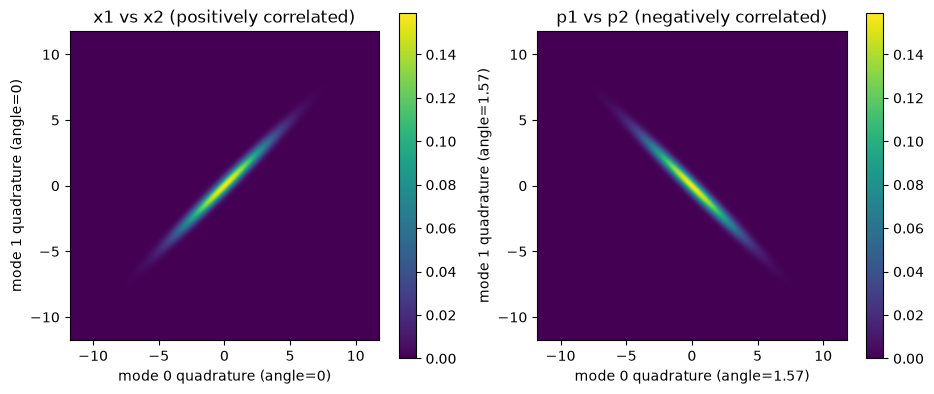

In [5]:
tmsv = cv.two_mode_squeezed(1.2)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
cv.visualization.plot_joint_marginal(tmsv, (0, 0.0), (1, 0.0), ax=axes[0])
axes[0].set_title("x1 vs x2 (positively correlated)")
cv.visualization.plot_joint_marginal(tmsv, (0, np.pi / 2), (1, np.pi / 2), ax=axes[1])
axes[1].set_title("p1 vs p2 (negatively correlated)")
fig.tight_layout()

## Gaussian steering

Steering quantifies whether Alice's local measurements can convince Bob
his state was "steered" -- a strictly stronger notion than entanglement,
sitting between entanglement and Bell nonlocality. For a symmetric TMSV,
steering is symmetric and grows with squeezing.

Text(0.5, 1.0, 'steering is symmetric for a pure symmetric TMSV')

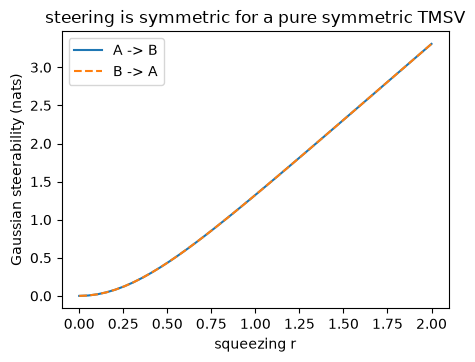

In [6]:
rs = np.linspace(0, 2.0, 40)
steering_ab = [cv.steerability(cv.two_mode_squeezed(r), [0], 1) for r in rs]
steering_ba = [cv.steerability(cv.two_mode_squeezed(r), [1], 0) for r in rs]

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.plot(rs, steering_ab, label="A -> B")
ax.plot(rs, steering_ba, "--", label="B -> A")
ax.set_xlabel("squeezing r")
ax.set_ylabel("Gaussian steerability (nats)")
ax.legend()
ax.set_title("steering is symmetric for a pure symmetric TMSV")

## Mutual information and entanglement of formation

For a *pure* global state, entanglement of formation and quantum discord
both exactly equal the reduced-state entropy (a general fact for pure
bipartite states), and the mutual information is exactly twice that.

In [7]:
tmsv = cv.two_mode_squeezed(0.9)
entropy = tmsv.reduced([0]).von_neumann_entropy()
print("reduced entropy:", entropy)
print("mutual information:", cv.mutual_information(tmsv, [0]), "(= 2x entropy for a pure state)")
print("entanglement of formation:", cv.entanglement_of_formation(tmsv, [0]))
print("discord:", cv.gaussian_discord(tmsv, [0], 1))

reduced entropy: 2.0527222341593494
mutual information: 4.1054444683187 (= 2x entropy for a pure state)
entanglement of formation: 2.0527222341593494
discord: 2.0527222341593494
